In [1]:
import pandas as pd

df = pd.read_csv("/content/data_core.csv")
df.head()

,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name
0,26.0,52.0,38.0,Sandy,Maize,37,0,0,Urea
1,29.0,52.0,45.0,Loamy,Sugarcane,12,0,36,DAP
2,34.0,65.0,62.0,Black,Cotton,7,9,30,14-35-14
3,32.0,62.0,34.0,Red,Tobacco,22,0,20,28-28
4,28.0,54.0,46.0,Clayey,Paddy,35,0,0,Urea


In [2]:
unique_classes = df["Fertilizer Name"].unique()
print("Number of unique classes:", len(unique_classes))
print("Classes:", unique_classes)

Number of unique classes: 7
Classes: ['Urea' 'DAP' '14-35-14' '28-28' '17-17-17' '20-20' '10-26-26']


In [3]:
class_counts = df["Fertilizer Name"].value_counts()
print(class_counts)

Fertilizer Name
14-35-14    1188
Urea        1170
DAP         1167
10-26-26    1128
17-17-17    1124
28-28       1120
20-20       1103
Name: count, dtype: int64


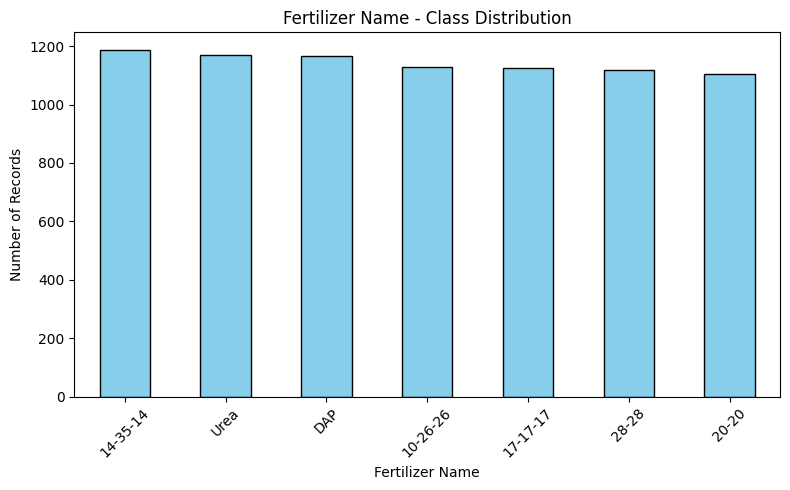

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
class_counts.plot(kind="bar", color="skyblue", edgecolor="black")
plt.title("Fertilizer Name - Class Distribution")
plt.xlabel("Fertilizer Name")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [5]:
print("Class balance summary:")
print(class_counts)
print("\nMax count:", class_counts.max(), " Min count:", class_counts.min())
print("Difference:", class_counts.max() - class_counts.min())

Class balance summary:
Fertilizer Name
14-35-14    1188
Urea        1170
DAP         1167
10-26-26    1128
17-17-17    1124
28-28       1120
20-20       1103
Name: count, dtype: int64

Max count: 1188  Min count: 1103
Difference: 85


In [6]:
print("Class balance summary:")
print(class_counts)
print("\nMax count:", class_counts.max(), " Min count:", class_counts.min())
print("Difference:", class_counts.max() - class_counts.min())

Class balance summary:
Fertilizer Name
14-35-14    1188
Urea        1170
DAP         1167
10-26-26    1128
17-17-17    1124
28-28       1120
20-20       1103
Name: count, dtype: int64

Max count: 1188  Min count: 1103
Difference: 85


In [7]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
encoded_target = le.fit_transform(df["Fertilizer Name"])

In [8]:
label_mapping = dict(zip(le.classes_, le.transform(le.classes_)))
print("Fertilizer Name -> Encoded Label mapping:")
for name, code in label_mapping.items():
    print(f"{name:10s} -> {code}")


Fertilizer Name -> Encoded Label mapping:
10-26-26   -> 0
14-35-14   -> 1
17-17-17   -> 2
20-20      -> 3
28-28      -> 4
DAP        -> 5
Urea       -> 6


In [9]:
# Original CSV remains untouched — df is unmodified
y_original = df["Fertilizer Name"].copy()
y_encoded = pd.Series(encoded_target, name="Fertilizer_Label")

comparison = pd.DataFrame({
    "Original_Target": y_original,
    "Encoded_Target": y_encoded
})
comparison.head(10)

,Original_Target,Encoded_Target
0,Urea,6
1,DAP,5
2,14-35-14,1
3,28-28,4
4,Urea,6
5,17-17-17,2
6,20-20,3
7,Urea,6
8,28-28,4
9,14-35-14,1


### Why Label Encoding is suitable for the target here

- The target "Fertilizer Name" is a nominal categorical variable with 7 classes, and it is the output the model must predict — not an input feature.
- Classification algorithms (e.g. Decision Tree, Random Forest, XGBoost) internally expect the target as a single integer array (0 to 6), not as text or multiple columns.
- Label Encoding does not imply any ordinal relationship here; the model treats each integer as a distinct class label, not as a ranked value — this is fine because the target is never fed into distance-based or linear arithmetic the way an input feature would be.
- It keeps the target as a single 1-D array (required by fit(X, y) in sklearn), unlike one-hot encoding, which would incorrectly expand the target into 7 separate columns.

### Why this differs from One-Hot Encoding of input features (Soil Type / Crop Type)

- Soil Type and Crop Type are input features, not the target. If label-encoded, models like Linear Regression or KNN could wrongly interpret the integers as having order/magnitude (e.g. "Loamy" > "Sandy"), which is meaningless for nominal categories.
- One-Hot Encoding avoids this by creating a separate binary (0/1) column per category, so no false ordinal relationship is introduced into the input space.
- The target doesn't have this problem because it's not used in arithmetic/distance calculations — it's simply the label the model tries to predict, so a single-column integer encoding (Label Encoding) is appropriate and expected by sklearn's classifiers.